# Ensemble Learning on Sri Lankan Used Car Prices
**Dataset:** Sri Lankan Vehicle (Car) Price Dataset (ikman.lk & riyasewana.lk), Kaggle

**Goal:** predict used car price (in lakhs) and compare ensemble methods:
- Baseline: single Decision Tree
- Bagging: Random Forest
- Boosting: XGBoost
- Stacking: Random Forest + XGBoost → Ridge
- Hybrid: Random Forest + ANN

Run top to bottom in Google Colab. Upload `car_price_dataset.csv` when asked.

> **AI assistance:** Claude (Anthropic) helped generate the code and explanations. Dataset choice, training, deployment and review of results by Harshana A.M.K.

## 1. Setup

In [1]:
!pip install -q xgboost

import time, json, warnings, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
RS = 42

In [2]:
# Upload the CSV (Colab). If running locally, just set the path.
try:
    from google.colab import files
    up = files.upload()
    PATH = list(up.keys())[0]
except ImportError:
    PATH = "car_price_dataset.csv"

df = pd.read_csv(PATH)
print(df.shape)
df.head()

Saving car_price_dataset.csv to car_price_dataset.csv
(9788, 17)


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


## 2. Data understanding

In [3]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9788 entries, 0 to 9787
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      9788 non-null   int64  
 1   Brand           9788 non-null   object 
 2   Model           9788 non-null   object 
 3   YOM             9788 non-null   int64  
 4   Engine (cc)     9788 non-null   float64
 5   Gear            9788 non-null   object 
 6   Fuel Type       9788 non-null   object 
 7   Millage(KM)     9788 non-null   float64
 8   Town            9788 non-null   object 
 9   Date            9788 non-null   object 
 10  Leasing         9788 non-null   object 
 11  Condition       9788 non-null   object 
 12  AIR CONDITION   9788 non-null   object 
 13  POWER STEERING  9788 non-null   object 
 14  POWER MIRROR    9788 non-null   object 
 15  POWER WINDOW    9788 non-null   object 
 16  Price           9788 non-null   float64
dtypes: float64(3), int64(2), object(1

,0
Unnamed: 0,9788
Brand,50
Model,1555
YOM,62
Engine (cc),278
Gear,2
Fuel Type,4
Millage(KM),62
Town,107
Date,65


In [4]:
df["Price"].describe()  # Price is in lakhs (1 lakh = Rs 100,000)

,Price
count,9788.000000
mean,53.464275
std,43.625049
min,2.650000
25%,26.250000
50%,43.000000
75%,69.750000
max,790.000000


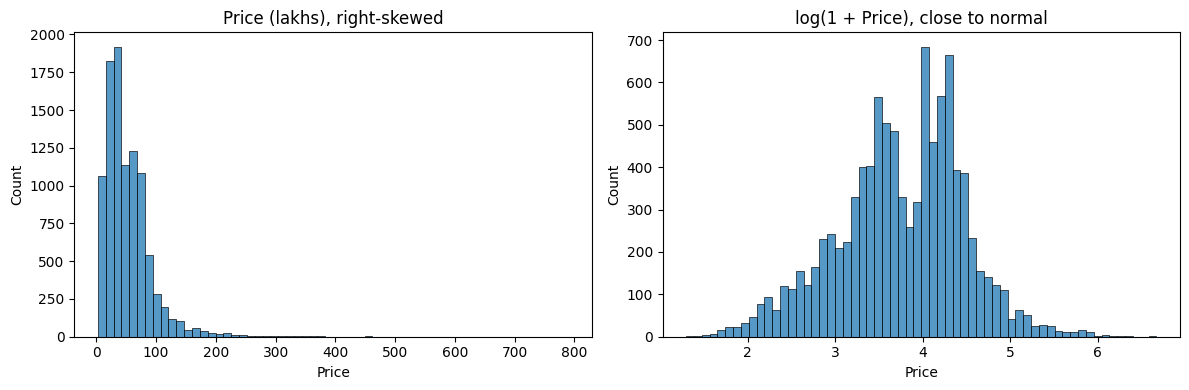

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price"], bins=60, ax=ax[0]).set_title("Price (lakhs), right-skewed")
sns.histplot(np.log1p(df["Price"]), bins=60, ax=ax[1]).set_title("log(1 + Price), close to normal")
plt.tight_layout(); plt.show()

### Data quality finding: Mileage is derived from Year
Mileage has exactly as many unique values as YOM and a correlation of -1.0 with it.
It looks like it was filled in as roughly 11,000 km per year of age, not real odometer readings.
So it carries **no extra information** and is dropped.

Unique YOM: 62 | Unique Mileage: 62
Correlation YOM vs Mileage: -1.0


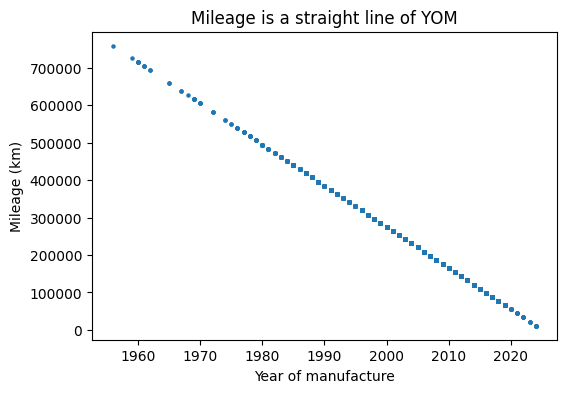

In [6]:
print("Unique YOM:", df["YOM"].nunique(), "| Unique Mileage:", df["Millage(KM)"].nunique())
print("Correlation YOM vs Mileage:", round(df["YOM"].corr(df["Millage(KM)"]), 6))
plt.figure(figsize=(6, 4))
plt.scatter(df["YOM"], df["Millage(KM)"], s=5)
plt.xlabel("Year of manufacture"); plt.ylabel("Mileage (km)"); plt.title("Mileage is a straight line of YOM")
plt.show()

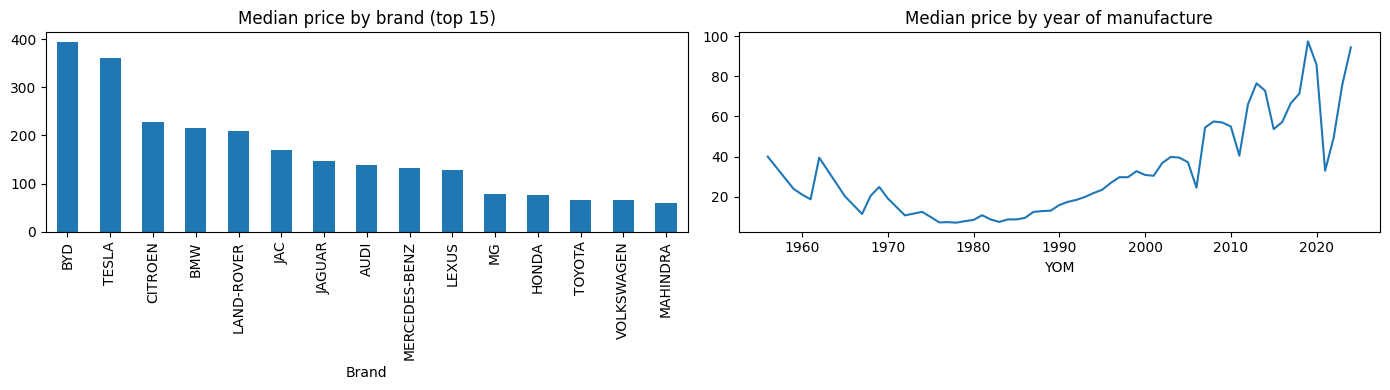

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("Brand")["Price"].median().sort_values(ascending=False).head(15).plot.bar(ax=ax[0], title="Median price by brand (top 15)")
df.groupby("YOM")["Price"].median().plot(ax=ax[1], title="Median price by year of manufacture")
plt.tight_layout(); plt.show()

### Relationships: engine size and town vs price

Correlation Engine (cc) vs log(Price): 0.066


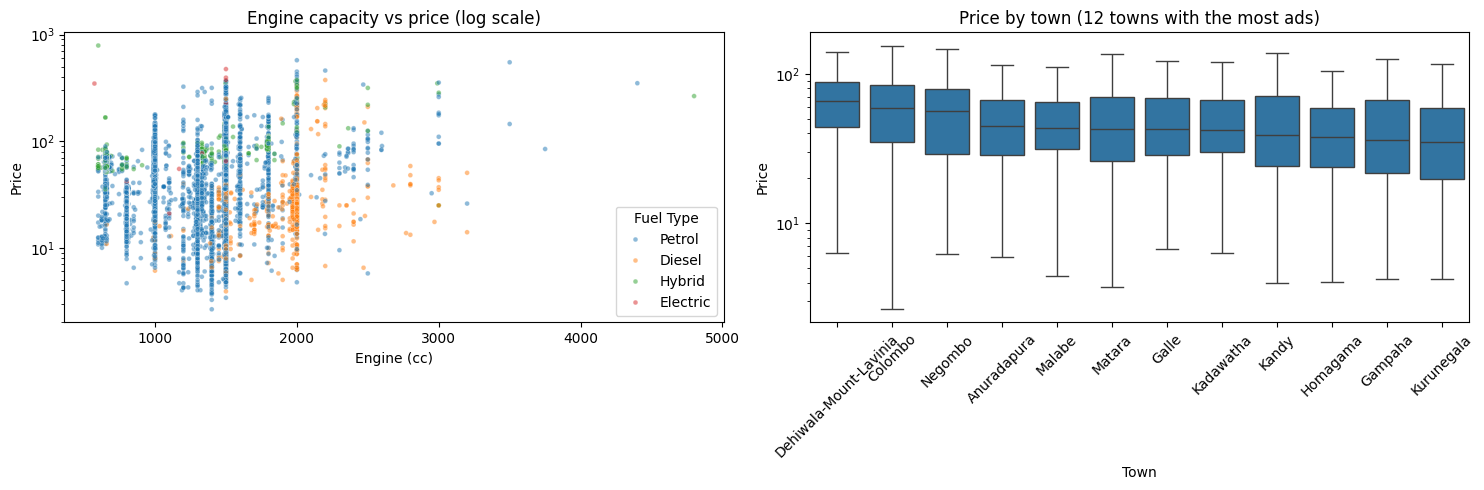

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df, x="Engine (cc)", y="Price", hue="Fuel Type", alpha=0.5, s=12, ax=ax[0])
ax[0].set_yscale("log"); ax[0].set_title("Engine capacity vs price (log scale)")
print("Correlation Engine (cc) vs log(Price):", round(df["Engine (cc)"].corr(np.log1p(df["Price"])), 3))

top_towns = df["Town"].value_counts().head(12).index
tdf = df[df["Town"].isin(top_towns)]
order = tdf.groupby("Town")["Price"].median().sort_values(ascending=False).index
sns.boxplot(data=tdf, x="Town", y="Price", order=order, showfliers=False, ax=ax[1])
ax[1].set_yscale("log"); ax[1].set_title("Price by town (12 towns with the most ads)")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [9]:
# Why is the engine vs price correlation so weak? Big engines are mostly old diesel vehicles.
print(df.groupby("Fuel Type")[["Engine (cc)", "YOM", "Price"]].median())
# Remove the effect of year from both, then correlate (partial correlation)
lp = np.log1p(df["Price"])
res_p = lp - np.polyval(np.polyfit(df["YOM"], lp, 1), df["YOM"])
res_e = df["Engine (cc)"] - np.polyval(np.polyfit(df["YOM"], df["Engine (cc)"], 1), df["YOM"])
print("Partial correlation Engine vs log(Price), controlling for year:", round(np.corrcoef(res_e, res_p)[0, 1], 3))

           Engine (cc)     YOM     Price
Fuel Type                               
Diesel          1970.0  1996.0  24.75000
Electric        1500.0  2014.0  54.40625
Hybrid          1490.0  2015.0  73.90000
Petrol          1300.0  2008.0  38.50000
Partial correlation Engine vs log(Price), controlling for year: 0.534


**Findings:**
- Engine size alone looks almost unrelated to price (correlation about 0.06), because most big-engine cars are old diesels. Comparing cars of the same year, bigger engines **do** cost more (partial correlation about 0.53). Year is a *confounder* here.
- Dehiwala-Mount Lavinia, Colombo and Negombo have the highest median prices, Kurunegala and Gampaha the lowest. The ranges overlap a lot, so location matters far less than brand, year and engine size.

## 3. Preprocessing

In [10]:
data = df.drop(columns=["Unnamed: 0", "Date", "Millage(KM)"])
data = data.drop_duplicates().reset_index(drop=True)
data["Age"] = 2025 - data["YOM"]

TARGET = "Price"
HIGH_CARD = ["Brand", "Model", "Town"]                       # many categories -> target encoding
LOW_CARD = ["Gear", "Fuel Type", "Leasing", "Condition",
            "AIR CONDITION", "POWER STEERING", "POWER MIRROR", "POWER WINDOW"]  # few categories -> one-hot
NUMERIC = ["YOM", "Age", "Engine (cc)"]
FEATURES = HIGH_CARD + LOW_CARD + NUMERIC

X = data[FEATURES]
y = np.log1p(data[TARGET])   # train on log price, convert back for metrics

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS)
print("Train:", X_train.shape, " Test:", X_test.shape)

def make_preprocessor(scale=False):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("te", TargetEncoder(random_state=RS), HIGH_CARD),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False), LOW_CARD),
        ("num", num, NUMERIC),
    ])

Train: (7628, 14)  Test: (1908, 14)


## 4. Train the models: baseline, bagging, boosting

In [11]:
models = {
    "Decision Tree (baseline)": DecisionTreeRegressor(random_state=RS),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, n_jobs=-1, random_state=RS),
    "XGBoost": XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=RS),
}
FAMILY = {"Decision Tree (baseline)": "Single model", "Random Forest": "Bagging", "XGBoost": "Boosting"}

def evaluate(name, y_true_log, y_pred_log, train_time, family):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {"Model": name, "Family": family,
            "R2": r2_score(yt, yp), "MAE (lakhs)": mean_absolute_error(yt, yp),
            "RMSE (lakhs)": np.sqrt(mean_squared_error(yt, yp)),
            "MAPE (%)": np.mean(np.abs((yt - yp) / yt)) * 100, "Train time (s)": train_time}

results, fitted, preds = [], {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    t0 = time.time(); pipe.fit(X_train, y_train); t = time.time() - t0
    p = pipe.predict(X_test)
    results.append(evaluate(name, y_test, p, t, FAMILY[name]))
    fitted[name], preds[name] = pipe, p
    print(f"{name:26s} R2={results[-1]['R2']:.3f}  MAE={results[-1]['MAE (lakhs)']:.2f}  time={t:.1f}s")

Decision Tree (baseline)   R2=0.870  MAE=6.96  time=0.1s
Random Forest              R2=0.901  MAE=5.39  time=5.1s
XGBoost                    R2=0.889  MAE=5.87  time=1.5s


## 5. Stacking: Random Forest + XGBoost → Ridge

**How it works:**
1. Two base models are trained: Random Forest (bagging) and XGBoost (boosting).
2. `StackingRegressor` creates their training-set predictions with **5-fold cross-validation** (out-of-fold), so the meta-model never sees predictions on cars a base model was trained on.
3. A **Ridge regression** meta-model learns the best weighted combination of the two predictions.

RF and XGBoost make different kinds of mistakes, so combining them can cancel some errors.

In [12]:
stack = StackingRegressor(
    estimators=[
        ("rf", RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, n_jobs=-1, random_state=RS)),
        ("xgb", XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=RS)),
    ],
    final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 13)), cv=5)

pipe = Pipeline([("prep", make_preprocessor()), ("model", stack)])
t0 = time.time(); pipe.fit(X_train, y_train); t = time.time() - t0
p = pipe.predict(X_test)
results.append(evaluate("Stacking", y_test, p, t, "Stacking"))
fitted["Stacking"], preds["Stacking"] = pipe, p
r = results[-1]
print(f"Stacking  R2={r['R2']:.3f}  MAE={r['MAE (lakhs)']:.2f}  time={t:.1f}s")

stack_weights = dict(zip(["Random Forest", "XGBoost"],
                         pipe.named_steps["model"].final_estimator_.coef_.round(3)))
print("Meta-model weights:", stack_weights)

Stacking  R2=0.904  MAE=5.45  time=57.0s
Meta-model weights: {'Random Forest': np.float64(0.502), 'XGBoost': np.float64(0.501)}


## 6. Hybrid model: Random Forest + ANN (a stacking variant)

**How it works (stacking):**
1. Random Forest is trained and makes *out-of-fold* predictions on the training set (so the ANN never sees leaked predictions).
2. The ANN (MLP neural network) gets the **original features + the RF prediction** as input.
3. RF captures the tree-style rules (brand, year thresholds), the ANN learns smooth corrections on top.

In [13]:
prep_ann = make_preprocessor(scale=True)
Xtr_p = prep_ann.fit_transform(X_train, y_train)
Xte_p = prep_ann.transform(X_test)

rf_base = RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, n_jobs=-1, random_state=RS)
t0 = time.time()
rf_oof = cross_val_predict(rf_base, Xtr_p, y_train, cv=KFold(5, shuffle=True, random_state=RS), n_jobs=-1)
rf_base.fit(Xtr_p, y_train)
rf_test = rf_base.predict(Xte_p)

# ANN on its own (for comparison)
ann = MLPRegressor(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=500, random_state=RS)
t_a = time.time(); ann.fit(Xtr_p, y_train); t_ann = time.time() - t_a
p_ann = ann.predict(Xte_p)

# Hybrid: ANN with RF prediction as an extra feature
hybrid_ann = MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=500, random_state=RS)
hybrid_ann.fit(np.column_stack([Xtr_p, rf_oof]), y_train)
p_hybrid = hybrid_ann.predict(np.column_stack([Xte_p, rf_test]))
t_h = time.time() - t0

results.append(evaluate("ANN (alone)", y_test, p_ann, t_ann, "Neural network"))
results.append(evaluate("Hybrid RF + ANN", y_test, p_hybrid, t_h, "Hybrid"))
preds["ANN (alone)"], preds["Hybrid RF + ANN"] = p_ann, p_hybrid
for r in results[-2:]:
    print(f"{r['Model']:26s} R2={r['R2']:.3f}  MAE={r['MAE (lakhs)']:.2f}")

ANN (alone)                R2=0.835  MAE=7.72
Hybrid RF + ANN            R2=0.900  MAE=5.69


## 7. Research experiment: LightGBM and CatBoost

The assignment asks to compare Random Forest with other gradient boosting methods (XGBoost, LightGBM, CatBoost).
Here LightGBM and CatBoost are trained on the **same split and preprocessing**, and compared with RF and XGBoost.
They are kept separate from the main results so the dashboard focuses on the core models.

In [14]:
!pip install -q lightgbm catboost
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

research_models = {
    "LightGBM": LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=31, colsample_bytree=0.8, random_state=RS, verbose=-1),
    "CatBoost": CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=6, random_seed=RS, verbose=0),
}
research = [r for r in results if r["Model"] in ["Random Forest", "XGBoost"]]
for name, model in research_models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    t0 = time.time(); pipe.fit(X_train, y_train); t = time.time() - t0
    research.append(evaluate(name, y_test, pipe.predict(X_test), t, "Boosting"))

research_df = pd.DataFrame(research)
os.makedirs("artifacts", exist_ok=True)
research_df.to_csv("artifacts/research_results.csv", index=False)
research_df.round(3)

,Model,Family,R2,MAE (lakhs),RMSE (lakhs),MAPE (%),Train time (s)
0,Random Forest,Bagging,0.901,5.392,14.588,13.415,5.074
1,XGBoost,Boosting,0.889,5.874,15.442,14.023,1.485
2,LightGBM,Boosting,0.908,5.883,14.118,14.402,1.399
3,CatBoost,Boosting,0.912,5.982,13.735,14.317,3.825


## 8. Stability check: 5-fold cross-validation

A single 80/20 split can be lucky or unlucky. Here the whole dataset is split into 5 parts, and each model is trained 5 times,
each time tested on a different part. If the ranking stays the same, the conclusions are reliable. (Stacking takes 1 to 2 minutes.)

In [15]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

mae_lakhs = make_scorer(lambda yt, yp: mean_absolute_error(np.expm1(yt), np.expm1(yp)), greater_is_better=False)
r2_lakhs = make_scorer(lambda yt, yp: r2_score(np.expm1(yt), np.expm1(yp)))
rf_ = lambda: RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, n_jobs=-1, random_state=RS)
xgb_ = lambda: XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=RS)
cv_models = {
    "Decision Tree (baseline)": DecisionTreeRegressor(random_state=RS),
    "Random Forest": rf_(),
    "XGBoost": xgb_(),
    "Stacking": StackingRegressor([("rf", rf_()), ("xgb", xgb_())], final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 13)), cv=5),
}
cv_rows = []
for name, model in cv_models.items():
    s = cross_validate(Pipeline([("prep", make_preprocessor()), ("model", model)]), X, y,
                       cv=KFold(5, shuffle=True, random_state=RS), scoring={"mae": mae_lakhs, "r2": r2_lakhs})
    cv_rows.append({"Model": name, "MAE mean": -s["test_mae"].mean(), "MAE std": s["test_mae"].std(),
                    "R2 mean": s["test_r2"].mean(), "R2 std": s["test_r2"].std(),
                    "MAE folds": ", ".join(f"{-v:.2f}" for v in s["test_mae"])})
    print(f"{name:26s} MAE = {cv_rows[-1]['MAE mean']:.2f} ± {cv_rows[-1]['MAE std']:.2f}   R2 = {cv_rows[-1]['R2 mean']:.3f}")
cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv("artifacts/cv_results.csv", index=False)

Decision Tree (baseline)   MAE = 6.96 ± 0.31   R2 = 0.778
Random Forest              MAE = 5.23 ± 0.16   R2 = 0.875
XGBoost                    MAE = 5.66 ± 0.21   R2 = 0.873
Stacking                   MAE = 5.27 ± 0.14   R2 = 0.881


**Finding:** the ranking matches the single split. Random Forest has the lowest error and stacking the best R². RF and stacking are within each other's spread (effectively tied), but RF beats XGBoost and every ensemble clearly beats the single tree.

## 9. Results

In [16]:
res = pd.DataFrame(results).sort_values("MAE (lakhs)").reset_index(drop=True)
res.style.format({"R2": "{:.3f}", "MAE (lakhs)": "{:.2f}", "RMSE (lakhs)": "{:.2f}",
                  "MAPE (%)": "{:.1f}", "Train time (s)": "{:.1f}"}).background_gradient(subset=["MAE (lakhs)"], cmap="RdYlGn_r")

,Model,Family,R2,MAE (lakhs),RMSE (lakhs),MAPE (%),Train time (s)
0,Random Forest,Bagging,0.901,5.39,14.59,13.4,5.1
1,Stacking,Stacking,0.904,5.45,14.41,13.3,57.0
2,Hybrid RF + ANN,Hybrid,0.900,5.69,14.69,13.7,39.8
3,XGBoost,Boosting,0.889,5.87,15.44,14.0,1.5
4,Decision Tree (baseline),Single model,0.870,6.96,16.72,17.3,0.1
5,ANN (alone),Neural network,0.835,7.72,18.87,16.7,4.2


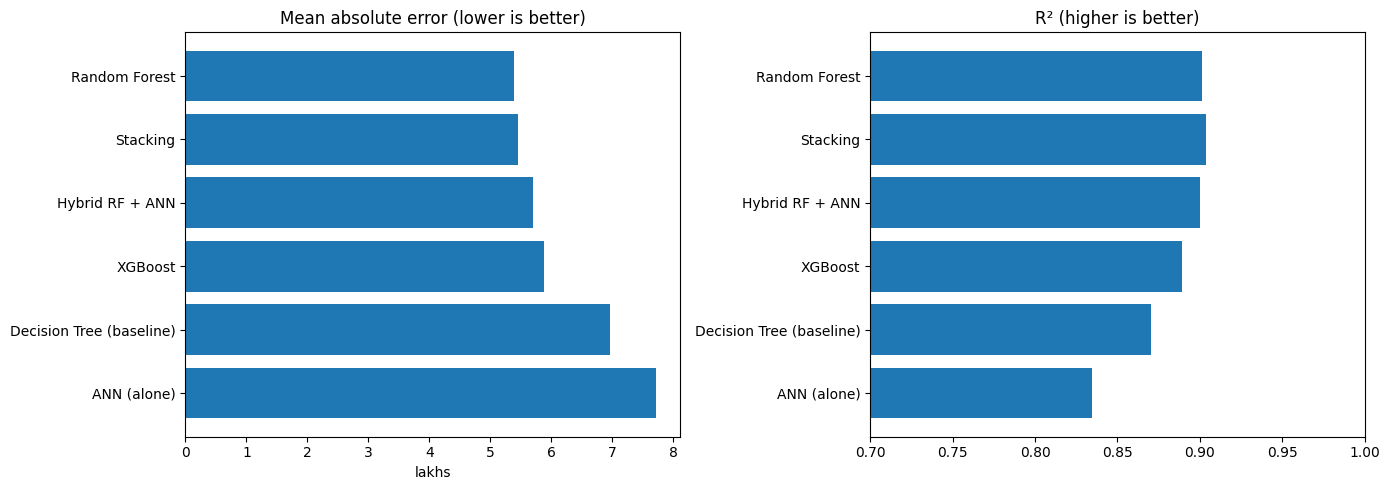

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
r = res.sort_values("MAE (lakhs)", ascending=False)
ax[0].barh(r["Model"], r["MAE (lakhs)"]); ax[0].set_title("Mean absolute error (lower is better)"); ax[0].set_xlabel("lakhs")
ax[1].barh(r["Model"], r["R2"]); ax[1].set_title("R² (higher is better)"); ax[1].set_xlim(0.7, 1)
plt.tight_layout(); plt.show()

### RF vs XGBoost head to head

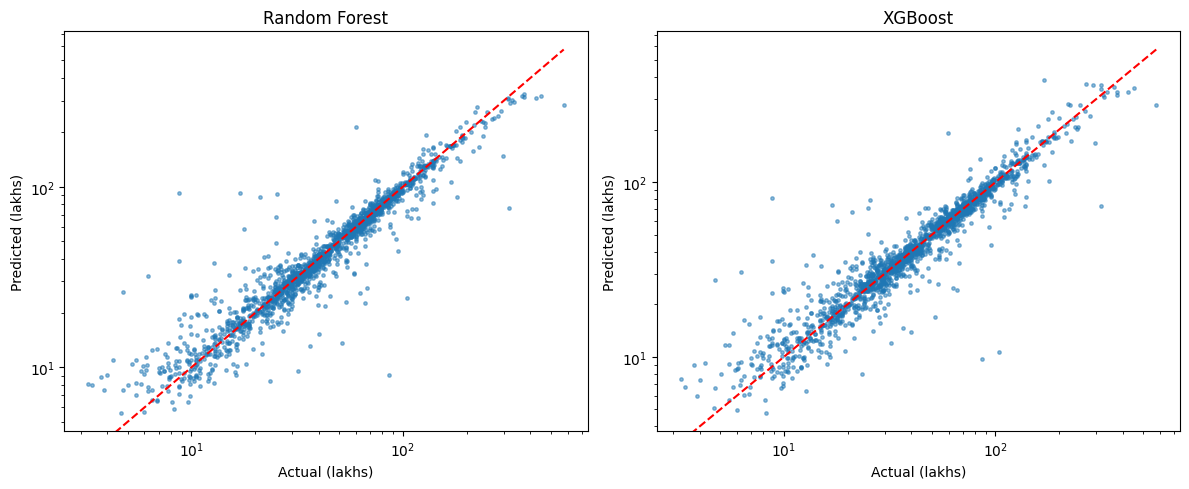

,Model,Family,R2,MAE (lakhs),RMSE (lakhs),MAPE (%),Train time (s)
0,Random Forest,Bagging,0.901235,5.391500,14.588287,13.414805,5.074380
3,XGBoost,Boosting,0.889343,5.873931,15.441629,14.022544,1.485388


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, name in zip(ax, ["Random Forest", "XGBoost"]):
    yt, yp = np.expm1(y_test), np.expm1(preds[name])
    a.scatter(yt, yp, s=6, alpha=0.5); m = yt.max()
    a.plot([0, m], [0, m], "r--"); a.set_xscale("log"); a.set_yscale("log")
    a.set_title(name); a.set_xlabel("Actual (lakhs)"); a.set_ylabel("Predicted (lakhs)")
plt.tight_layout(); plt.show()
res[res.Model.isin(["Random Forest", "XGBoost"])]

### Feature importance (RF vs XGBoost)

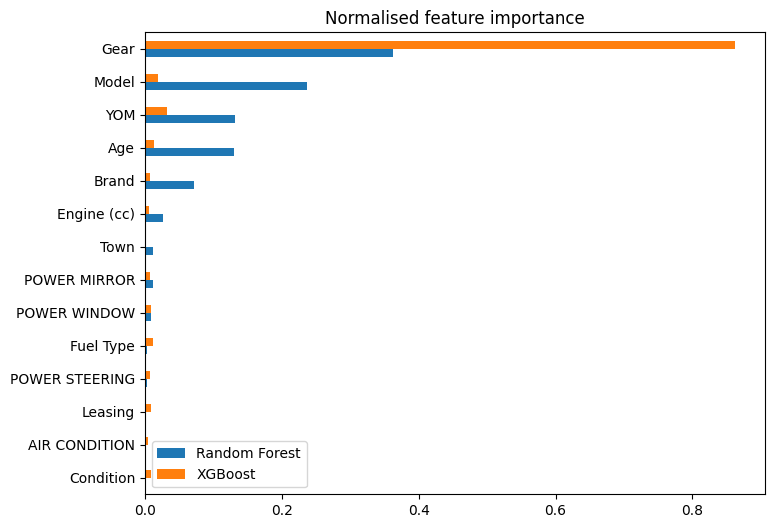

,Random Forest,XGBoost
Gear,0.361871,0.862773
Model,0.236312,0.018970
YOM,0.132191,0.031583
Age,0.130532,0.013576
Brand,0.071203,0.007960
Engine (cc),0.026595,0.005680
Town,0.011593,0.001749
POWER MIRROR,0.011017,0.007471
POWER WINDOW,0.009069,0.009426
Fuel Type,0.003443,0.011344


In [19]:
def importances(name):
    pipe = fitted[name]
    names = pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
    # merge one-hot columns back to their original feature
    orig = [n.split("__", 1)[1] for n in names]
    orig = [next((f for f in FEATURES if o == f or o.startswith(f + "_")), o) for o in orig]
    return imp.groupby(orig).sum().sort_values(ascending=False)

fi = pd.DataFrame({"Random Forest": importances("Random Forest"), "XGBoost": importances("XGBoost")})
fi = fi / fi.sum()
fi.sort_values("Random Forest").plot.barh(figsize=(8, 6), title="Normalised feature importance")
plt.show()
fi.sort_values("Random Forest", ascending=False)

## 10. Save everything for the dashboard

In [20]:
os.makedirs("artifacts", exist_ok=True)
res.to_csv("artifacts/results.csv", index=False)
fi.to_csv("artifacts/feature_importance.csv")
pd.DataFrame({"actual": np.expm1(y_test.values),
              **{k: np.expm1(v) for k, v in preds.items()}}).to_csv("artifacts/test_predictions.csv", index=False)

json.dump({k: float(v) for k, v in stack_weights.items()}, open("artifacts/stacking_weights.json", "w"))
for name in ["Random Forest", "XGBoost", "Stacking"]:
    joblib.dump(fitted[name], f"artifacts/{name.replace(' ', '_').lower()}.pkl", compress=3)
joblib.dump({"prep": prep_ann, "rf": rf_base, "ann": hybrid_ann}, "artifacts/hybrid_rf_ann.pkl", compress=3)

# options for the dashboard input form
meta = {"brand_models": data.groupby("Brand")["Model"].unique().apply(sorted).apply(list).to_dict(),
        "towns": sorted(data["Town"].unique()), "low_card": {c: sorted(data[c].unique()) for c in LOW_CARD},
        "yom_range": [int(data.YOM.min()), int(data.YOM.max())], "features": FEATURES}
json.dump(meta, open("artifacts/meta.json", "w"))
data.to_csv("artifacts/clean_data.csv", index=False)

!zip -qr artifacts.zip artifacts
try:
    files.download("artifacts.zip")
except NameError:
    print("Saved to artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Research: RF vs Gradient Boosting

| | Random Forest (bagging) | Gradient Boosting (XGBoost / LightGBM / CatBoost) |
|---|---|---|
| How trees are built | Independently, in parallel, on bootstrap samples | Sequentially, each tree fixes the errors of the previous ones |
| Main thing it reduces | Variance | Bias (and variance with regularisation) |
| Tuning effort | Low, good results with defaults | Higher (learning rate, depth, n_estimators) |
| Overfitting risk | Low | Higher if not regularised / early stopped |
| Speed (in this project) | Slowest here (about 11 s), even though trees train in parallel | Much faster: XGBoost and LightGBM about 1.5 s, CatBoost about 3.5 s |
| Categorical data | Needs encoding | CatBoost handles natively |

**Tabular vs image/text data**
- On **tabular** data (like this one) tree ensembles are usually the best choice: they handle mixed feature types, need little preprocessing and often beat neural networks.
- On **images and text**, tree ensembles struggle: they can't learn spatial patterns (pixels) or word order/meaning. CNNs and transformers are far better there. Trees can still be useful **on top of extracted features** (e.g. CNN embeddings or TF-IDF).

## 12. Conclusion
- All ensembles beat the single decision tree, which shows the main benefit of ensemble learning: combining models reduces error.
- **Random Forest** had the lowest average error (about 5.4 lakhs). **Stacking** (RF + XGBoost → Ridge) had the best R², by combining the two almost equally.
- **XGBoost** was slightly less accurate than RF here, but trained several times faster. With hyperparameter tuning, boosting models usually improve further.
- The **hybrid RF + ANN** greatly improved the neural network but did not beat Random Forest, which shows that tree ensembles are very strong on tabular data.
- 5-fold cross-validation gave the same ranking, so the conclusions are reliable.
- **Limitations:** default hyperparameters, asking prices rather than sale prices, and no real mileage or condition details.